
# Analisis dan Klasifikasi Tutupan Lahan Provinsi Jawa Timur Berbasis Citra Sentinel-2A

## 1. Business Understanding

### 1.1 Latar Belakang

Tutupan lahan merupakan informasi penting untuk memahami kondisi geografis Provinsi Jawa Timur, seperti kawasan pertanian, permukiman, hutan, mangrove, dan perairan. Identifikasi tutupan lahan dapat dilakukan menggunakan citra satelit Sentinel-2A yang menyediakan informasi spektral permukaan bumi.

Pada proyek ini, citra Sentinel-2A diolah menggunakan Sistem Informasi Geografis (SIG) untuk memperoleh fitur berupa lima band spektral, yaitu B02, B03, B04, B08, dan B11, serta dua indeks spektral, yaitu NDVI dan NDWI. Dataset yang digunakan terdiri atas 272 data sampel yang dibagi menjadi data pelatihan (*training*) dan data pengujian (*testing*) dengan perbandingan 80:20, yaitu sekitar 217 data training dan 55 data testing.

Klasifikasi dilakukan menggunakan algoritma **Random Forest** untuk memprediksi kelas tutupan lahan berdasarkan fitur yang tersedia. Performa model dievaluasi menggunakan metrik akurasi, *classification report*, dan *confusion matrix*. Hasil klasifikasi selanjutnya disajikan dalam bentuk peta digital untuk mendukung analisis spasial tutupan lahan di Provinsi Jawa Timur.

### 1.2 Tujuan Proyek

Tujuan dari proyek ini adalah:

1. Mengidentifikasi karakteristik tutupan lahan di Provinsi Jawa Timur berdasarkan citra Sentinel-2A.
2. Mengolah band spektral dan indeks spektral sebagai fitur klasifikasi.
3. Membangun model klasifikasi tutupan lahan menggunakan algoritma Random Forest.
4. Mengevaluasi performa model menggunakan data testing.
5. Menghasilkan peta digital hasil klasifikasi tutupan lahan.

## 2. Data Understanding

### 2.1 Sumber dan Karakteristik Data

Data yang digunakan dalam proyek ini terdiri atas citra satelit Sentinel-2A Level-2A dan data sampel geospasial yang berisi informasi kelas tutupan lahan. Citra satelit berfungsi sebagai sumber informasi spektral, sedangkan data sampel digunakan sebagai acuan dalam proses pelatihan model.

Pengambilan citra dilakukan melalui layanan openEO dengan memanfaatkan koleksi data Copernicus. Data citra diproses menggunakan komposit median untuk merangkum pengamatan dalam periode yang ditentukan. Selanjutnya, nilai piksel pada lokasi sampel diekstraksi untuk membentuk dataset yang digunakan dalam klasifikasi.

### 2.2 Kategori Tutupan Lahan

Klasifikasi dirancang untuk membedakan enam kategori tutupan lahan, yaitu:

1. **Sawah:** lahan pertanian yang digunakan untuk budidaya tanaman.
2. **Bangunan:** kawasan permukiman dan permukaan terbangun.
3. **Hutan:** wilayah yang didominasi oleh pepohonan.
4. **Mangrove:** vegetasi yang tumbuh di lingkungan pesisir.
5. **Danau:** badan air yang berada di daratan.
6. **Lautan:** wilayah perairan laut.

Setiap kategori direpresentasikan menggunakan label numerik agar dapat diproses oleh algoritma klasifikasi. Ketersediaan sampel untuk setiap kategori perlu diperiksa sebelum model dilatih.

### 2.3 Deskripsi Fitur dan Perhitungan Indeks Spektral

Klasifikasi tutupan lahan menggunakan tujuh fitur, yaitu lima band spektral Sentinel-2A dan dua indeks spektral, NDVI dan NDWI, sebagai masukan model Random Forest.

**A. Band Spektral Sentinel-2A**

- **B02 (Blue):** Memberikan informasi pantulan spektrum biru, terutama pada perairan.
- **B03 (Green):** Memberikan informasi karakteristik vegetasi dan perairan.
- **B04 (Red):** Membantu analisis vegetasi dan digunakan dalam perhitungan NDVI.
- **B08 (NIR):** Membedakan karakteristik vegetasi dan air serta digunakan dalam perhitungan NDVI dan NDWI.
- **B11 (SWIR):** Membantu membedakan karakteristik kelembapan permukaan, tanah, dan vegetasi.

**B. NDVI (Normalized Difference Vegetation Index)**

NDVI digunakan untuk menggambarkan tingkat kehijauan vegetasi dan membantu membedakan vegetasi dari nonvegetasi. Perhitungannya menggunakan band B08 dan B04.

**C. NDWI (Normalized Difference Water Index)**

NDWI digunakan untuk membantu mengidentifikasi badan air dan membedakannya dari vegetasi maupun kawasan terbangun. Perhitungannya menggunakan band B03 dan B08.



### 2.4 Instalasi Library

In [3]:
pip install geopandas

In [4]:
pip install openeo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 357.8/357.8 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 2.2 MB/s eta 0:00:00


In [5]:
%pip install scikit-learn

In [6]:
pip install rasterio

In [7]:
pip install seaborn

In [105]:
!pip install -q geopandas openeo shapely

## 3. Data Preparation

Tahap persiapan data dilakukan sebelum proses pemodelan untuk memastikan data sampel dan citra Sentinel-2A siap digunakan. Tahapan ini meliputi penggabungan data sampel tutupan lahan dari Shapefile, pengambilan nilai piksel berdasarkan lokasi sampel, perhitungan indeks spektral NDVI dan NDWI, serta pembersihan data dari nilai yang tidak valid. Hasil akhirnya disimpan dalam format CSV yang berisi fitur spektral, indeks vegetasi dan air, serta label kelas tutupan lahan untuk digunakan pada tahap pemodelan Random Forest.


### 3.1 Pengumpulan dan Penggabungan Data Sampel Tutupan Lahan

In [107]:

from google.colab import files
import geopandas as gpd
import pandas as pd
import zipfile
import io

# 1. Upload file ZIP melalui Choose File
uploaded = files.upload()

# 2. Membaca file berdasarkan nama yang diunggah
daftar_kelas = {
    "sawah": ("Sawah", 0),
    "bangunan": ("Bangunan", 1),
    "hutan": ("Hutan", 2),
    "mangrove": ("Mangrove", 3),
    "danau": ("Danau", 4),
    "lautan": ("Lautan", 5)
}

kumpulan_data = []

for nama_file, isi_file in uploaded.items():
    nama_dasar = nama_file.lower().replace(".zip", "")

    kelas_ditemukan = None

    for kata_kunci, informasi in daftar_kelas.items():
        if kata_kunci in nama_dasar:
            kelas_ditemukan = informasi
            break

    if kelas_ditemukan is None:
        print("File dilewati karena nama kelas tidak dikenali:", nama_file)
        continue

    with zipfile.ZipFile(io.BytesIO(isi_file)) as arsip:
        nama_shp = [
            nama for nama in arsip.namelist()
            if nama.lower().endswith(".shp")
        ]

        if not nama_shp:
            print("Tidak ditemukan file SHP:", nama_file)
            continue

        with arsip.open(nama_shp[0]) as file_shp:
            data = gpd.read_file(
                "zip://" + nama_file + "!/" + nama_shp[0]
            ) if False else None

        # Membaca shapefile langsung dari ZIP yang diunggah
        data = gpd.read_file(
            "zip:///" + "/content/" + nama_file + "!/" + nama_shp[0]
        )

    if data.crs is None:
        raise ValueError("CRS tidak ditemukan pada " + nama_file)

    data = data.to_crs("EPSG:4326")

    nama_kelas, kode_kelas = kelas_ditemukan
    data["label_teks"] = nama_kelas
    data["label"] = kode_kelas

    kumpulan_data.append(data)

    print(nama_kelas, ":", len(data), "sampel")

# 3. Menggabungkan semua data
if not kumpulan_data:
    raise ValueError("Tidak ada dataset yang berhasil dibaca.")

data_gabungan = gpd.GeoDataFrame(
    pd.concat(kumpulan_data, ignore_index=True),
    crs="EPSG:4326"
)

print("\nTotal sampel:", len(data_gabungan))
print(data_gabungan["label_teks"].value_counts())

# 4. Menentukan batas wilayah
min_x, min_y, max_x, max_y = data_gabungan.total_bounds
buffer = 0.005

batas_wilayah = {
    "west": float(min_x - buffer),
    "south": float(min_y - buffer),
    "east": float(max_x + buffer),
    "north": float(max_y + buffer)
}

print("\nBatas wilayah:", batas_wilayah)


Saving bangunan.zip to bangunan (3).zip
Saving danau.zip to danau (3).zip
Saving hutan.zip to hutan (3).zip
Saving lautan.zip to lautan (3).zip
Saving mangrove.zip to mangrove (3).zip
Saving sawah_jatim.zip to sawah_jatim (3).zip
Bangunan : 50 sampel
Danau : 22 sampel
Hutan : 50 sampel
Lautan : 50 sampel
Mangrove : 50 sampel
Sawah : 50 sampel

Total sampel: 272
label_teks
Bangunan    50
Hutan       50
Mangrove    50
Lautan      50
Sawah       50
Danau       22
Name: count, dtype: int64

Batas wilayah: {'west': 111.209496, 'south': -8.785424, 'east': 114.61055499999999, 'north': -7.1464680000000005}


### 3.2 Pengambilan dan Pengolahan Citra Sentinel-2A



In [55]:

import openeo
import time
import os

# 1. Koneksi ke Copernicus Data Space
koneksi = openeo.connect(
    "openeo.dataspace.copernicus.eu"
)

koneksi.authenticate_oidc()

# 2. Mengambil koleksi Sentinel-2
kubus_citra = koneksi.load_collection(
    "SENTINEL2_L2A",
    spatial_extent=batas_wilayah,
    temporal_extent=["2026-01-01", "2026-09-01"],
    bands=["B02", "B03", "B04", "B08", "B11"],
    max_cloud_cover=10
)

# 3. Membuat komposit median
komposit_citra = kubus_citra.median_time()

# 4. Mengatur resolusi spasial
komposit_citra = komposit_citra.resample_spatial(
    resolution=0.001,
    projection=4326
)

# 5. Membuat dan menjalankan batch job
job_citra = komposit_citra.create_job(
    title="Sentinel2_Klasifikasi_Multikelas",
    out_format="GTiff"
)

job_citra.start()

# 6. Memantau proses
status = job_citra.status()

while status in ["created", "queued", "running"]:
    print("Status pemrosesan:", status)
    time.sleep(30)
    status = job_citra.status()

# 7. Mengunduh hasil
folder_output = "hasil_sentinel2"

if status == "finished":
    os.makedirs(folder_output, exist_ok=True)
    job_citra.download_results(folder_output)

    print("Berhasil! Hasil citra disimpan di:", folder_output)

    # Menampilkan file hasil
    print(os.listdir(folder_output))

else:
    print("Job gagal dengan status:", status)

    for log in job_citra.logs():
        print(log)


Authenticated using refresh token.
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: queued
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running
Status pemrosesan: running

/tmp/ipykernel_59176/1000495113.py:51: UserDeprecationWarning: Call to deprecated method download_results. (Instead use `BatchJob.get_results` and the more flexible download functionality of `JobResults`) -- Deprecated since version 0.4.10.
  job_citra.download_results(folder_output)
/usr/local/lib/python3.13/dist-packages/openeo/rest/job.py:193: UserDeprecationWarning: Call to deprecated method get_result. (Use `BatchJob.get_results` instead.) -- Deprecated since version 0.4.10.
  return self.get_result().download_files(target)
/usr/local/lib/python3.13/dist-packages/openeo/rest/job.py:197: UserDeprecationWarning: Call to deprecated class _Result. (Use `JobResults` instead) -- Deprecated since version 0.4.10.
  return _Result(self)


Berhasil! Hasil citra disimpan di: hasil_sentinel2
['openEO.tif']


### 3.3 Pemeriksaan dan Identifikasi File Citra

Tahap ini dilakukan untuk memeriksa file dan folder yang tersedia pada lingkungan Google Colab setelah proses pengambilan citra Sentinel-2A. Pemeriksaan dilakukan dengan menampilkan lokasi kerja, daftar file dan folder, serta mencari file citra dengan ekstensi `.tif` atau `.tiff` di dalam direktori `/content`.

File GeoTIFF yang ditemukan selanjutnya dapat digunakan pada tahap pemeriksaan informasi citra dan ekstraksi nilai piksel. Tahap ini membantu memastikan keberadaan file citra hasil pengolahan sebelum proses persiapan data dilanjutkan.

In [56]:

import os

print("Lokasi kerja Colab:", os.getcwd())
print("\nIsi folder kerja:")

for nama in os.listdir("."):
    if os.path.isdir(nama):
        print(f"[FOLDER] {nama}")
    else:
        print(f"[FILE]   {nama}")

print("\nMencari file GeoTIFF di seluruh folder kerja...")

for akar, folder, daftar_file in os.walk("/content"):
    for nama in daftar_file:
        if nama.lower().endswith((".tif", ".tiff")):
            print("Ditemukan:", os.path.join(akar, nama))


Lokasi kerja Colab: /content

Isi folder kerja:
[FILE]   lautan (1).zip
[FILE]   danau.zip
[FOLDER] hasil_sentinel2
[FILE]   mangrove (1).zip
[FILE]   lautan.zip
[FILE]   hutan (1).zip
[FILE]   mangrove.zip
[FILE]   dataset_uts_klasifikasi.csv
[FILE]   bangunan (1).zip
[FILE]   sawah_jatim (1).zip
[FILE]   sawah_jatim.zip
[FILE]   danau (1).zip
[FILE]   hutan.zip
[FILE]   bangunan.zip

Mencari file GeoTIFF di seluruh folder kerja...
Ditemukan: /content/hasil_sentinel2/openEO.tif


### 3.4 Pemeriksaan Informasi dan Metadata Citra Sentinel-2A

Tahap ini dilakukan untuk memeriksa informasi dasar citra Sentinel-2A hasil pengolahan yang tersimpan dalam format GeoTIFF. Pemeriksaan menggunakan library Rasterio untuk membaca metadata citra, meliputi format file, jumlah band, ukuran raster, sistem koordinat (CRS), resolusi spasial, batas koordinat, dan tipe data setiap band.

Informasi tersebut digunakan untuk mengetahui karakteristik teknis citra sebelum dilakukan ekstraksi nilai piksel. Pemeriksaan ini juga membantu memastikan bahwa file citra dapat dibaca dan informasi spasialnya tersedia untuk mendukung proses pengolahan data selanjutnya.

In [57]:

import os
import rasterio

file_citra = "/content/hasil_sentinel2/openEO.tif"

with rasterio.open(file_citra) as src:
    print("File citra berhasil dibaca!")
    print("Format:", src.driver)
    print("Jumlah band:", src.count)
    print("Ukuran raster:", src.width, "x", src.height)
    print("CRS:", src.crs)
    print("Resolusi:", src.res)
    print("Batas koordinat:", src.bounds)
    print("Tipe data:", src.dtypes)


File citra berhasil dibaca!
Format: GTiff
Jumlah band: 5
Ukuran raster: 3402 x 1640
CRS: EPSG:4326
Resolusi: (0.0010000000000000002, 0.0009999999999999994)
Batas koordinat: BoundingBox(left=111.20948320931704, bottom=-8.786054103228544, right=114.61148320931704, top=-7.146054103228545)
Tipe data: ('int16', 'int16', 'int16', 'int16', 'int16')


### 3.5 Ekstraksi Nilai Piksel Citra Berdasarkan Sampel Tutupan Lahan


In [58]:

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio

print("=== DATA PREPARATION ===")

file_raster = "/content/hasil_sentinel2/openEO.tif"

if not os.path.exists(file_raster):
    raise FileNotFoundError(
        f"Raster tidak ditemukan: {file_raster}"
    )

# Cari variabel data sampel yang tersedia
if "data_latih" in globals():
    sampel = data_latih.copy()
elif "gdf_gabungan" in globals():
    sampel = gdf_gabungan.copy()
else:
    raise NameError(
        "Data sampel belum tersedia. Jalankan kode "
        "pembacaan dan penggabungan ZIP terlebih dahulu."
    )

print("Kolom data sampel:", sampel.columns.tolist())
print("Jumlah sampel:", len(sampel))

# Deteksi kolom kelas dan label secara otomatis
pilihan_kelas = [
    "kategori", "label_teks", "kelas", "Kelas",
    "class", "nama_kelas", "jenis"
]
pilihan_label = [
    "kode_kelas", "label", "Label", "kode",
    "class_id", "id_kelas"
]

kolom_kelas = next(
    (c for c in pilihan_kelas if c in sampel.columns), None
)
kolom_label = next(
    (c for c in pilihan_label if c in sampel.columns), None
)

# Jika kolom nama kelas tidak tersedia, gunakan label numerik
if kolom_kelas is None and kolom_label is not None:
    peta_kelas = {
        0: "Sawah",
        1: "Bangunan",
        2: "Hutan",
        3: "Mangrove",
        4: "Danau",
        5: "Lautan"
    }
    sampel["Kelas"] = (
        pd.to_numeric(sampel[kolom_label], errors="coerce")
        .map(peta_kelas)
    )
    kolom_kelas = "Kelas"

if kolom_label is None and kolom_kelas is not None:
    peta_label = {
        "Sawah": 0,
        "Bangunan": 1,
        "Lahan Hijau": 2,
        "Hutan": 2,
        "Mangrove": 3,
        "Danau": 4,
        "Ranu": 4,
        "Lautan": 5,
        "Perairan Laut": 5
    }
    sampel["Label"] = sampel[kolom_kelas].map(peta_label)
    kolom_label = "Label"

if kolom_kelas is None or kolom_label is None:
    raise ValueError(
        "Kolom kelas/label tidak berhasil dikenali. "
        "Periksa daftar kolom yang tercetak di atas."
    )

# Pastikan geometri tersedia
sampel = sampel[
    sampel.geometry.notna() & ~sampel.geometry.is_empty
].copy()

with rasterio.open(file_raster) as src:
    print("\nCRS raster:", src.crs)
    print("Jumlah band:", src.count)
    print("Ukuran raster:", src.width, "x", src.height)

    if src.count < 5:
        raise ValueError("Raster harus memiliki minimal 5 band.")

    # Hitung titik tengah di CRS proyeksi
    sampel_utm = sampel.to_crs(sampel.estimate_utm_crs())
    titik_utm = sampel_utm.geometry.centroid
    titik_raster = gpd.GeoSeries(
        titik_utm, crs=sampel_utm.crs
    ).to_crs(src.crs)

    koordinat = list(zip(titik_raster.x, titik_raster.y))

    # Ambil nilai piksel dan ubah ke float agar NaN dapat digunakan
    piksel = np.ma.vstack(
        list(src.sample(koordinat, masked=True))
    )
    nilai_band = piksel.astype(np.float32).filled(np.nan)

    # Periksa piksel di luar batas raster
    for i, (x, y) in enumerate(koordinat):
        row, col = src.index(x, y)
        if not (
            0 <= row < src.height and
            0 <= col < src.width
        ):
            nilai_band[i, :] = np.nan

# Susun dataset
df_dataset = pd.DataFrame(
    nilai_band[:, :5],
    columns=["B02", "B03", "B04", "B08", "B11"]
)

df_dataset["Kelas"] = sampel[kolom_kelas].to_numpy()
df_dataset["Label"] = sampel[kolom_label].to_numpy()

titik_wgs84 = sampel_utm.geometry.centroid.to_crs("EPSG:4326")
df_dataset["Longitude"] = titik_wgs84.x.to_numpy()
df_dataset["Latitude"] = titik_wgs84.y.to_numpy()

print("\nEkstraksi piksel selesai.")
print("Jumlah sampel awal:", len(df_dataset))
display(df_dataset.head())


=== DATA PREPARATION ===
Kolom data sampel: ['FID', 'geometry', 'kelas', 'label']
Jumlah sampel: 272

CRS raster: EPSG:4326
Jumlah band: 5
Ukuran raster: 3402 x 1640

Ekstraksi piksel selesai.
Jumlah sampel awal: 272


,B02,B03,B04,B08,B11,Kelas,Label,Longitude,Latitude
0,1117.0,1268.0,1521.0,1766.0,2878.0,Bangunan,1,112.718531,-7.249539
1,1091.0,1221.0,1379.0,1609.0,2176.0,Bangunan,1,112.721986,-7.247514
2,1087.0,1235.0,1339.0,1456.0,1695.0,Bangunan,1,112.724004,-7.245616
3,872.0,1092.0,1375.0,2051.0,2675.0,Bangunan,1,112.724291,-7.247208
4,1109.0,1215.0,1316.0,1460.0,1718.0,Bangunan,1,112.724945,-7.246042


### 3.6 Perhitungan Indeks Spektral dan Pembersihan Dataset

Tahap ini dilakukan untuk menghitung indeks spektral NDVI dan NDWI berdasarkan nilai band citra Sentinel-2A yang telah diekstraksi. NDVI digunakan untuk menggambarkan kondisi vegetasi, sedangkan NDWI digunakan untuk membantu mengidentifikasi karakteristik badan air.

Perhitungan NDVI menggunakan band inframerah dekat (B08) dan merah (B04), dengan rumus:

$$
NDVI=\frac{B08-B04}{B08+B04+10^{-6}}
$$

Sementara itu, NDWI dihitung menggunakan band hijau (B03) dan inframerah dekat (B08), dengan rumus:

$$
NDWI=\frac{B03-B08}{B03+B08+10^{-6}}
$$

Penambahan nilai \(10^{-6}\) pada penyebut bertujuan untuk menghindari pembagian dengan nol. Setelah indeks spektral dihitung, dilakukan pembersihan dataset dengan mengganti nilai tak hingga menjadi nilai kosong dan menghapus baris yang memiliki nilai kosong pada kolom wajib. Dataset kemudian disimpan dalam format CSV agar dapat digunakan pada tahap pemodelan klasifikasi tutupan lahan.

Pada tahap akhir, kode menampilkan jumlah sampel valid, jumlah kolom, dan distribusi sampel pada setiap kelas. File dataset juga diunduh agar dapat digunakan untuk proses analisis selanjutnya.

In [60]:

# Hitung NDVI dan NDWI
df_dataset["NDVI"] = (
    (df_dataset["B08"] - df_dataset["B04"]) /
    (df_dataset["B08"] + df_dataset["B04"] + 1e-6)
)

df_dataset["NDWI"] = (
    (df_dataset["B03"] - df_dataset["B08"]) /
    (df_dataset["B03"] + df_dataset["B08"] + 1e-6)
)

# Bersihkan nilai tak valid
df_dataset.replace([np.inf, -np.inf], np.nan, inplace=True)

kolom_wajib = [
    "B02", "B03", "B04", "B08", "B11",
    "Kelas", "Label", "Longitude", "Latitude"
]

df_dataset.dropna(subset=kolom_wajib, inplace=True)
df_dataset.reset_index(drop=True, inplace=True)

# Simpan CSV
nama_csv = "/content/dataset_uts_klasifikasi.csv"
df_dataset.to_csv(
    nama_csv,
    index=False,
    encoding="utf-8-sig"
)

print("=== DATA PREPARATION SELESAI ===")
print("Jumlah sampel valid:", len(df_dataset))
print("Jumlah kolom:", len(df_dataset.columns))
print("File tersimpan:", nama_csv)

print("\nJumlah sampel per kelas:")
print(df_dataset["Kelas"].value_counts())

print("\nPreview dataset:")
display(df_dataset.head(10))

# Unduh CSV ke komputer
from google.colab import files
files.download(nama_csv)


=== DATA PREPARATION SELESAI ===
Jumlah sampel valid: 272
Jumlah kolom: 11
File tersimpan: /content/dataset_uts_klasifikasi.csv

Jumlah sampel per kelas:
Kelas
Bangunan    50
Hutan       50
Mangrove    50
Lautan      50
Sawah       50
Danau       22
Name: count, dtype: int64

Preview dataset:


,B02,B03,B04,B08,B11,Kelas,Label,Longitude,Latitude,NDVI,NDWI
0,1117.0,1268.0,1521.0,1766.0,2878.0,Bangunan,1,112.718531,-7.249539,0.074536,-0.164140
1,1091.0,1221.0,1379.0,1609.0,2176.0,Bangunan,1,112.721986,-7.247514,0.076975,-0.137102
2,1087.0,1235.0,1339.0,1456.0,1695.0,Bangunan,1,112.724004,-7.245616,0.041860,-0.082126
3,872.0,1092.0,1375.0,2051.0,2675.0,Bangunan,1,112.724291,-7.247208,0.197315,-0.305122
4,1109.0,1215.0,1316.0,1460.0,1718.0,Bangunan,1,112.724945,-7.246042,0.051873,-0.091589
5,1317.0,1366.0,1595.0,1698.0,2713.0,Bangunan,1,112.726343,-7.245956,0.031278,-0.108355
6,1220.0,1373.0,1554.0,1729.0,2789.0,Bangunan,1,112.726290,-7.246877,0.053305,-0.114765
7,1244.0,1274.0,1471.0,1519.0,2786.0,Bangunan,1,112.726166,-7.247502,0.016054,-0.087719
8,1289.0,1382.0,1618.0,1807.0,2716.0,Bangunan,1,112.726110,-7.248077,0.055182,-0.133271
9,567.0,765.0,1085.0,1759.0,2043.0,Bangunan,1,112.728046,-7.245395,0.236990,-0.393819


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4. Modeling dan Evaluation Matriks

PEMETAAN LABEL DAN DISTRIBUSI DATA


,Label,Nama Kelas,Jumlah Data
0,0,Sawah,50
1,1,Bangunan,50
2,2,Hutan,50
3,3,Mangrove,50
4,4,Danau,22
5,5,Lautan,50


Total data valid: 272

PEMBAGIAN DATA TRAINING DAN TESTING
Total data     : 272
Data training  : 217
Data testing   : 55
Jumlah fitur   : 7

Distribusi kelas training:


,Jumlah
Label,
Sawah,40
Bangunan,40
Hutan,40
Mangrove,40
Danau,17
Lautan,40


Distribusi kelas testing:


,Jumlah
Label,
Sawah,10
Bangunan,10
Hutan,10
Mangrove,10
Danau,5
Lautan,10



TRAINING RANDOM FOREST
Training selesai.
Fitur model: ['B02', 'B03', 'B04', 'B08', 'B11', 'NDVI', 'NDWI']
Label model: [0 1 2 3 4 5]

EVALUASI RANDOM FOREST
Jumlah data testing : 55
Prediksi benar      : 49
Prediksi salah      : 6
Akurasi testing     : 89.09%

CLASSIFICATION REPORT


,precision,recall,f1-score,support
Sawah,0.889,0.800,0.842,10.000
Bangunan,1.000,1.000,1.000,10.000
Hutan,1.000,0.900,0.947,10.000
Mangrove,0.750,0.900,0.818,10.000
Danau,0.750,0.600,0.667,5.000
Lautan,0.909,1.000,0.952,10.000
accuracy,0.891,0.891,0.891,0.891
macro avg,0.883,0.867,0.871,55.000
weighted avg,0.895,0.891,0.890,55.000



CONFUSION MATRIX
Baris = kelas aktual, kolom = kelas prediksi


,Sawah,Bangunan,Hutan,Mangrove,Danau,Lautan
Sawah,8,0,0,2,0,0
Bangunan,0,10,0,0,0,0
Hutan,0,0,9,1,0,0
Mangrove,0,0,0,9,1,0
Danau,1,0,0,0,3,1
Lautan,0,0,0,0,0,10


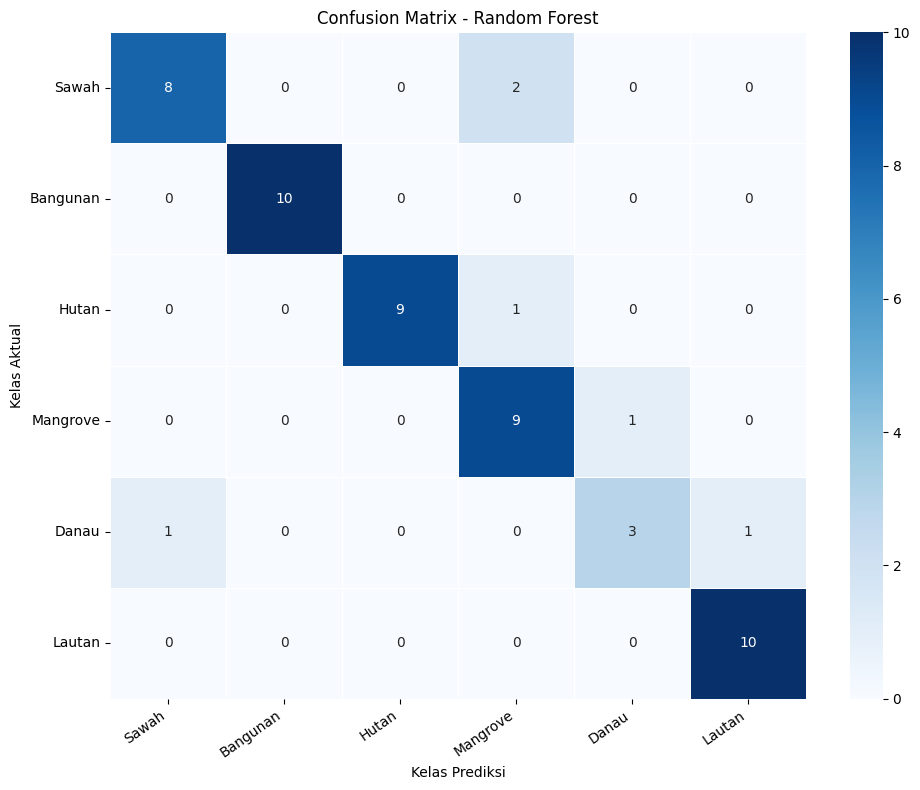


RINGKASAN JENIS KESALAHAN


,Kelas Aktual,Diprediksi Sebagai,Jumlah Kesalahan
0,Sawah,Mangrove,2
1,Hutan,Mangrove,1
2,Mangrove,Danau,1
3,Danau,Sawah,1
4,Danau,Lautan,1



EKSPOR HASIL
File hasil tersimpan di: /content/hasil_random_forest
ZIP hasil: /content/hasil_random_forest.zip

Model deployment: model_random_forest.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [61]:


import os
import shutil
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. PERSIAPAN DATA
# ============================================================

fitur_kolom = [
    "B02", "B03", "B04", "B08", "B11", "NDVI", "NDWI"
]

# Mapping harus sama dengan cell deployment
nama_kelas = {
    0: "Sawah",
    1: "Bangunan",
    2: "Hutan",
    3: "Mangrove",
    4: "Danau",
    5: "Lautan"
}

label_urut = list(nama_kelas.keys())
nama_urut = list(nama_kelas.values())

if "df_dataset" not in globals():
    raise NameError(
        "df_dataset belum tersedia. Jalankan cell preprocessing terlebih dahulu."
    )

data_model = df_dataset.copy()

kolom_dibutuhkan = fitur_kolom + ["Label"]

kolom_hilang = [
    kolom for kolom in kolom_dibutuhkan
    if kolom not in data_model.columns
]

if kolom_hilang:
    raise ValueError(
        f"Kolom berikut tidak ditemukan: {kolom_hilang}"
    )

# Pastikan fitur dan label berupa angka
for kolom in kolom_dibutuhkan:
    data_model[kolom] = pd.to_numeric(
        data_model[kolom], errors="coerce"
    )

data_model.replace([np.inf, -np.inf], np.nan, inplace=True)
data_model.dropna(subset=kolom_dibutuhkan, inplace=True)

# Hanya gunakan label bilangan bulat 0 sampai 5
data_model = data_model[
    data_model["Label"].isin(label_urut)
    & (data_model["Label"] % 1 == 0)
].copy()

data_model["Label"] = data_model["Label"].astype(int)

if data_model.empty:
    raise ValueError("Tidak ada data valid untuk pemodelan.")

# Periksa jumlah sampel setiap kelas
jumlah_kelas = (
    data_model["Label"]
    .value_counts()
    .reindex(label_urut, fill_value=0)
)

print("=" * 60)
print("PEMETAAN LABEL DAN DISTRIBUSI DATA")
print("=" * 60)

display(pd.DataFrame({
    "Label": label_urut,
    "Nama Kelas": nama_urut,
    "Jumlah Data": jumlah_kelas.values
}))

print("Total data valid:", len(data_model))

kelas_kurang = jumlah_kelas[jumlah_kelas < 2]

if not kelas_kurang.empty:
    raise ValueError(
        "Setiap kelas harus memiliki minimal 2 sampel. "
        f"Kelas yang kurang data: {kelas_kurang.to_dict()}"
    )

# ============================================================
# 2. PEMBAGIAN DATA TRAINING DAN TESTING
# ============================================================

print("\n" + "=" * 60)
print("PEMBAGIAN DATA TRAINING DAN TESTING")
print("=" * 60)

X = data_model[fitur_kolom].copy()
y = data_model["Label"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=21,
    stratify=y
)

print("Total data     :", len(data_model))
print("Data training  :", len(X_train))
print("Data testing   :", len(X_test))
print("Jumlah fitur   :", len(fitur_kolom))

print("\nDistribusi kelas training:")
display(
    y_train.value_counts()
    .reindex(label_urut, fill_value=0)
    .rename(index=nama_kelas)
    .rename("Jumlah")
    .to_frame()
)

print("Distribusi kelas testing:")
display(
    y_test.value_counts()
    .reindex(label_urut, fill_value=0)
    .rename(index=nama_kelas)
    .rename("Jumlah")
    .to_frame()
)

# ============================================================
# 3. TRAINING RANDOM FOREST
# ============================================================

print("\n" + "=" * 60)
print("TRAINING RANDOM FOREST")
print("=" * 60)

model_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight="balanced",
    random_state=21,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

print("Training selesai.")
print("Fitur model:", list(model_rf.feature_names_in_))
print("Label model:", model_rf.classes_)

# ============================================================
# 4. EVALUASI PADA DATA TESTING
# ============================================================

print("\n" + "=" * 60)
print("EVALUASI RANDOM FOREST")
print("=" * 60)

y_pred = model_rf.predict(X_test)

akurasi = accuracy_score(y_test, y_pred)
jumlah_benar = int((y_test.to_numpy() == y_pred).sum())
jumlah_salah = len(y_test) - jumlah_benar

print("Jumlah data testing :", len(y_test))
print("Prediksi benar      :", jumlah_benar)
print("Prediksi salah      :", jumlah_salah)
print(f"Akurasi testing     : {akurasi * 100:.2f}%")

print("\nCLASSIFICATION REPORT")

laporan = classification_report(
    y_test,
    y_pred,
    labels=label_urut,
    target_names=nama_urut,
    output_dict=True,
    zero_division=0
)

display(pd.DataFrame(laporan).transpose().round(3))

# ============================================================
# 5. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=label_urut
)

tabel_cm = pd.DataFrame(
    cm,
    index=nama_urut,
    columns=nama_urut
)

print("\nCONFUSION MATRIX")
print("Baris = kelas aktual, kolom = kelas prediksi")

display(tabel_cm)

plt.figure(figsize=(10, 8))

sns.heatmap(
    tabel_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Kelas Prediksi")
plt.ylabel("Kelas Aktual")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ============================================================
# 6. RINGKASAN JENIS KESALAHAN
# ============================================================

print("\n" + "=" * 60)
print("RINGKASAN JENIS KESALAHAN")
print("=" * 60)

data_salah = pd.DataFrame({
    "Label Aktual": y_test.to_numpy(),
    "Label Prediksi": y_pred
})

data_salah = data_salah[
    data_salah["Label Aktual"] != data_salah["Label Prediksi"]
].copy()

if data_salah.empty:
    ringkasan_salah = pd.DataFrame(columns=[
        "Kelas Aktual",
        "Diprediksi Sebagai",
        "Jumlah Kesalahan"
    ])
    print("Tidak ada kesalahan pada data testing.")

else:
    ringkasan_salah = (
        data_salah
        .groupby(["Label Aktual", "Label Prediksi"])
        .size()
        .reset_index(name="Jumlah Kesalahan")
    )

    ringkasan_salah["Kelas Aktual"] = (
        ringkasan_salah["Label Aktual"].map(nama_kelas)
    )

    ringkasan_salah["Diprediksi Sebagai"] = (
        ringkasan_salah["Label Prediksi"].map(nama_kelas)
    )

    ringkasan_salah = (
        ringkasan_salah[[
            "Kelas Aktual",
            "Diprediksi Sebagai",
            "Jumlah Kesalahan"
        ]]
        .sort_values("Jumlah Kesalahan", ascending=False)
        .reset_index(drop=True)
    )

    display(ringkasan_salah)

# ============================================================
# 7. SIMPAN MODEL DAN HASIL EVALUASI
# ============================================================

print("\n" + "=" * 60)
print("EKSPOR HASIL")
print("=" * 60)

folder_hasil = "/content/hasil_random_forest"
os.makedirs(folder_hasil, exist_ok=True)

# Simpan model terbaru untuk deployment
joblib.dump(
    model_rf,
    os.path.join(folder_hasil, "model_random_forest.pkl")
)

# Simpan mapping kelas
joblib.dump(
    nama_kelas,
    os.path.join(folder_hasil, "mapping_kelas.pkl")
)

# Simpan classification report
pd.DataFrame(laporan).transpose().to_csv(
    os.path.join(folder_hasil, "classification_report.csv")
)

# Simpan confusion matrix
tabel_cm.to_csv(
    os.path.join(folder_hasil, "confusion_matrix.csv")
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    tabel_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Kelas Prediksi")
plt.ylabel("Kelas Aktual")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(
        folder_hasil,
        "confusion_matrix_random_forest.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# Simpan ringkasan kesalahan
ringkasan_salah.to_csv(
    os.path.join(folder_hasil, "ringkasan_jenis_kesalahan.csv"),
    index=False
)

# Simpan prediksi data testing
hasil_testing = X_test.copy()
hasil_testing["Label Aktual"] = y_test
hasil_testing["Label Prediksi"] = y_pred
hasil_testing["Nama Aktual"] = y_test.map(nama_kelas)
hasil_testing["Nama Prediksi"] = pd.Series(
    y_pred, index=y_test.index
).map(nama_kelas)

hasil_testing.to_csv(
    os.path.join(folder_hasil, "hasil_testing.csv"),
    index=False
)

# Buat ZIP hasil
file_zip = shutil.make_archive(
    folder_hasil,
    "zip",
    folder_hasil
)

print("File hasil tersimpan di:", folder_hasil)
print("ZIP hasil:", file_zip)
print("\nModel deployment: model_random_forest.pkl")

files.download(file_zip)


## 5. Deployment

Model berhasil dimuat.
Kelas model: [0 1 2 3 4 5]
Fitur model: ['B02' 'B03' 'B04' 'B08' 'B11' 'NDVI' 'NDWI']

INFORMASI RASTER
Ukuran: 3402 x 1640
Jumlah band: 5
CRS: EPSG:4326
Deskripsi band: ('B02', 'B03', 'B04', 'B08', 'B11')
Memproses: 512 dari 1640 baris
Memproses: 1024 dari 1640 baris
Memproses: 1536 dari 1640 baris
Memproses: 1640 dari 1640 baris

KOREKSI KELAS PERAIRAN
Danau: 2329982 -> 17258
Lautan: 31159 -> 2343883

GeoTIFF tersimpan: /content/hasil_deployment/hasil_klasifikasi_lulc.tif

STATISTIK HASIL KLASIFIKASI


,Label,Kelas,Jumlah Piksel,Persentase (%)
0,0,Sawah,985049,17.66
1,1,Bangunan,453197,8.12
2,2,Hutan,1700348,30.48
3,3,Mangrove,79027,1.42
4,4,Danau,17258,0.31
5,5,Lautan,2343883,42.01


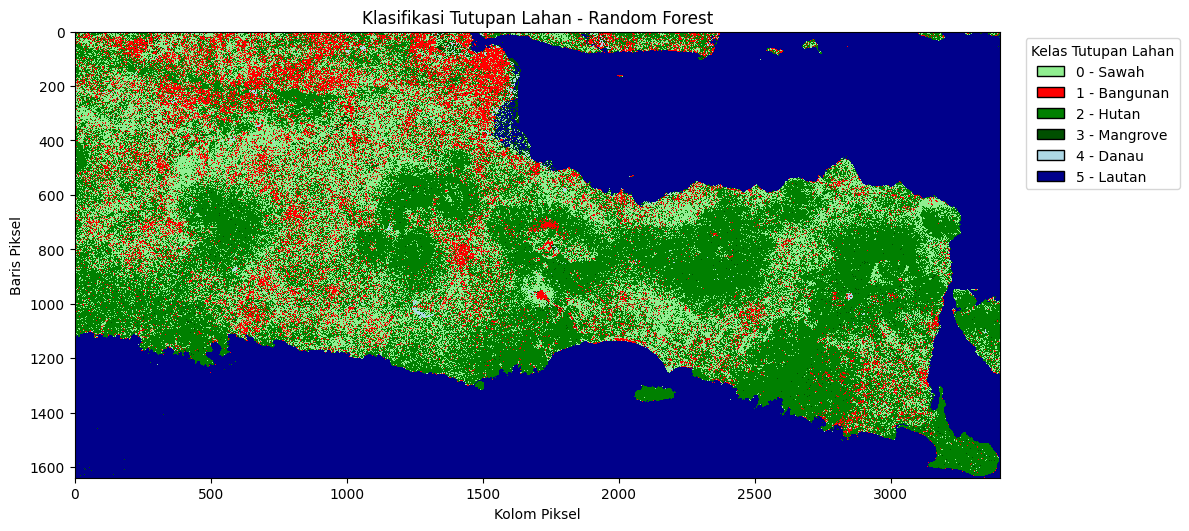


SEMUA HASIL SELESAI
Folder: /content/hasil_deployment
ZIP: /content/hasil_deployment.zip

Daftar file:
- statistik_klasifikasi.csv
- hasil_klasifikasi_lulc.tif
- peta_klasifikasi_lulc.png
- mapping_kelas.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [108]:

import os
import shutil
import joblib
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from google.colab import files
from scipy import ndimage
from IPython.display import display


# ============================================================
# 1. PATH FILE DAN PEMUATAN MODEL
# ============================================================

raster_path = "/content/hasil_sentinel2/openEO.tif"
folder_model = "/content/hasil_random_forest"
model_path = os.path.join(folder_model, "model_random_forest.pkl")

folder_output = "/content/hasil_deployment"
os.makedirs(folder_output, exist_ok=True)

if not os.path.exists(model_path):
    raise FileNotFoundError(f"Model tidak ditemukan: {model_path}")

if not os.path.exists(raster_path):
    raise FileNotFoundError(f"Raster tidak ditemukan: {raster_path}")

model = joblib.load(model_path)

fitur_kolom = [
    "B02", "B03", "B04", "B08", "B11", "NDVI", "NDWI"
]

nama_kelas = {
    0: "Sawah",
    1: "Bangunan",
    2: "Hutan",
    3: "Mangrove",
    4: "Danau",
    5: "Lautan"
}

warna_rgb = {
    0: (144, 238, 144),
    1: (255, 0, 0),
    2: (0, 128, 0),
    3: (0, 80, 0),
    4: (173, 216, 230),
    5: (0, 0, 139)
}

print("Model berhasil dimuat.")
print("Kelas model:", model.classes_)
print("Fitur model:", model.feature_names_in_)

if list(model.feature_names_in_) != fitur_kolom:
    raise ValueError(
        "Urutan fitur tidak sesuai dengan model training."
    )


# ============================================================
# 2. MEMBACA RASTER DAN MEMERIKSA BAND
# ============================================================

with rasterio.open(raster_path) as src:

    print("\nINFORMASI RASTER")
    print("Ukuran:", src.width, "x", src.height)
    print("Jumlah band:", src.count)
    print("CRS:", src.crs)
    print("Deskripsi band:", src.descriptions)

    band_diperlukan = ["B02", "B03", "B04", "B08", "B11"]
    deskripsi_band = list(src.descriptions or ())

    if not all(band in deskripsi_band for band in band_diperlukan):
        raise ValueError(
            "Nama band tidak lengkap pada metadata raster. "
            "Periksa deskripsi dan urutan band terlebih dahulu."
        )

    indeks_band = {
        band: deskripsi_band.index(band) + 1
        for band in band_diperlukan
    }

    tinggi = src.height
    lebar = src.width
    profil = src.profile.copy()
    nodata_sumber = src.nodata

    hasil_prediksi = np.full(
        (tinggi, lebar),
        255,
        dtype=np.uint8
    )


    # ========================================================
    # 3. PREDIKSI RANDOM FOREST PER BLOK
    # ========================================================

    ukuran_blok = 512

    for row_start in range(0, tinggi, ukuran_blok):

        for col_start in range(0, lebar, ukuran_blok):

            tinggi_blok = min(ukuran_blok, tinggi - row_start)
            lebar_blok = min(ukuran_blok, lebar - col_start)

            window = rasterio.windows.Window(
                col_start,
                row_start,
                lebar_blok,
                tinggi_blok
            )

            data_band = {}

            for nama, nomor in indeks_band.items():
                data_band[nama] = src.read(
                    nomor,
                    window=window
                ).astype(np.float32)

            mask_valid = np.ones(
                (tinggi_blok, lebar_blok),
                dtype=bool
            )

            for nama in indeks_band:
                nilai = data_band[nama]

                mask_valid &= np.isfinite(nilai)
                mask_valid &= nilai != -32768

                if nodata_sumber is not None:
                    if np.isnan(nodata_sumber):
                        mask_valid &= ~np.isnan(nilai)
                    else:
                        mask_valid &= nilai != nodata_sumber

            B03 = data_band["B03"]
            B04 = data_band["B04"]
            B08 = data_band["B08"]

            # Rumus harus sama dengan preprocessing training
            NDVI = (B08 - B04) / (B08 + B04 + 1e-6)
            NDWI = (B03 - B08) / (B03 + B08 + 1e-6)

            mask_valid &= np.isfinite(NDVI)
            mask_valid &= np.isfinite(NDWI)

            if not np.any(mask_valid):
                continue

            X_blok = pd.DataFrame({
                "B02": data_band["B02"][mask_valid],
                "B03": data_band["B03"][mask_valid],
                "B04": data_band["B04"][mask_valid],
                "B08": data_band["B08"][mask_valid],
                "B11": data_band["B11"][mask_valid],
                "NDVI": NDVI[mask_valid],
                "NDWI": NDWI[mask_valid]
            })

            prediksi = model.predict(X_blok[fitur_kolom])

            blok_hasil = hasil_prediksi[
                row_start:row_start + tinggi_blok,
                col_start:col_start + lebar_blok
            ]

            blok_hasil[mask_valid] = prediksi.astype(np.uint8)

        print(
            "Memproses:",
            min(row_start + ukuran_blok, tinggi),
            "dari",
            tinggi,
            "baris"
        )


# ============================================================
# 4. KOREKSI KELAS DANAU DAN LAUTAN
# ============================================================

LUAS_MIN_LAUT = 5000
LUAS_MIN_TEPI = 200

mask_air = np.isin(hasil_prediksi, [4, 5])

sebelum_danau = int((hasil_prediksi == 4).sum())
sebelum_laut = int((hasil_prediksi == 5).sum())

label_air, jumlah_air = ndimage.label(
    mask_air,
    structure=np.ones((3, 3), dtype=int)
)

if jumlah_air > 0:

    luas_air = np.bincount(label_air.ravel())

    id_tepi = np.unique(np.concatenate([
        label_air[0, :],
        label_air[-1, :],
        label_air[:, 0],
        label_air[:, -1]
    ]))

    menyentuh_tepi = np.zeros(jumlah_air + 1, dtype=bool)
    menyentuh_tepi[id_tepi] = True

    komponen_laut = (
        (luas_air >= LUAS_MIN_LAUT)
        | (
            menyentuh_tepi
            & (luas_air >= LUAS_MIN_TEPI)
        )
    )

    komponen_laut[0] = False

    mask_laut = komponen_laut[label_air]

    hasil_prediksi[mask_air & mask_laut] = 5
    hasil_prediksi[mask_air & ~mask_laut] = 4

print("\nKOREKSI KELAS PERAIRAN")
print(
    "Danau:",
    sebelum_danau,
    "->",
    int((hasil_prediksi == 4).sum())
)
print(
    "Lautan:",
    sebelum_laut,
    "->",
    int((hasil_prediksi == 5).sum())
)


# ============================================================
# 5. MENYIMPAN HASIL KLASIFIKASI KE GEOTIFF
# ============================================================

output_tif = os.path.join(
    folder_output,
    "hasil_klasifikasi_lulc.tif"
)

profil.update(
    driver="GTiff",
    count=1,
    dtype="uint8",
    nodata=255,
    compress="lzw"
)

with rasterio.open(output_tif, "w", **profil) as dst:
    dst.write(hasil_prediksi, 1)
    dst.set_band_description(1, "Kelas LULC")

    dst.update_tags(
        kelas_0="Sawah",
        kelas_1="Bangunan",
        kelas_2="Hutan",
        kelas_3="Mangrove",
        kelas_4="Danau",
        kelas_5="Lautan"
    )

print("\nGeoTIFF tersimpan:", output_tif)


# ============================================================
# 6. STATISTIK HASIL KLASIFIKASI
# ============================================================

mask_valid = hasil_prediksi != 255
total_piksel = int(mask_valid.sum())

if total_piksel == 0:
    raise ValueError(
        "Tidak ada piksel valid yang berhasil diklasifikasikan."
    )

statistik = []

for label, nama in nama_kelas.items():

    jumlah = int(np.sum(hasil_prediksi == label))
    persentase = jumlah / total_piksel * 100

    statistik.append({
        "Label": label,
        "Kelas": nama,
        "Jumlah Piksel": jumlah,
        "Persentase (%)": round(persentase, 2)
    })

df_statistik = pd.DataFrame(statistik)

print("\nSTATISTIK HASIL KLASIFIKASI")
display(df_statistik)

output_csv = os.path.join(
    folder_output,
    "statistik_klasifikasi.csv"
)

df_statistik.to_csv(output_csv, index=False)


# ============================================================
# 7. VISUALISASI PETA KLASIFIKASI
# ============================================================

warna_urut = [
    np.array(warna_rgb[i], dtype=float) / 255
    for i in range(6)
]

cmap = ListedColormap(warna_urut)
cmap.set_bad("white")

norm = BoundaryNorm(
    np.arange(-0.5, 6.5, 1),
    cmap.N
)

peta_masked = np.ma.masked_equal(hasil_prediksi, 255)

fig, ax = plt.subplots(figsize=(12, 9))

ax.imshow(
    peta_masked,
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)

legenda = [
    Patch(
        facecolor=np.array(warna_rgb[i]) / 255,
        edgecolor="black",
        label=f"{i} - {nama_kelas[i]}"
    )
    for i in range(6)
]

ax.legend(
    handles=legenda,
    title="Kelas Tutupan Lahan",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

ax.set_title("Klasifikasi Tutupan Lahan - Random Forest")
ax.set_xlabel("Kolom Piksel")
ax.set_ylabel("Baris Piksel")

plt.tight_layout()

output_png = os.path.join(
    folder_output,
    "peta_klasifikasi_lulc.png"
)

plt.savefig(
    output_png,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 8. MENYIMPAN MAPPING KELAS
# ============================================================

output_mapping = os.path.join(
    folder_output,
    "mapping_kelas.csv"
)

pd.DataFrame([
    {
        "Label": label,
        "Kelas": nama_kelas[label],
        "Warna_RGB": str(warna_rgb[label])
    }
    for label in nama_kelas
]).to_csv(output_mapping, index=False)


# ============================================================
# 9. MEMBUAT ZIP HASIL DEPLOYMENT
# ============================================================

file_zip = shutil.make_archive(
    "/content/hasil_deployment",
    "zip",
    root_dir=folder_output
)

print("\nSEMUA HASIL SELESAI")
print("Folder:", folder_output)
print("ZIP:", file_zip)

print("\nDaftar file:")
for nama_file in os.listdir(folder_output):
    print("-", nama_file)

files.download(file_zip)
